# push-lab demo

The core story of [SPEC Section 3](../docs/SPEC.md), told from the committed results in `results/`. Nothing here reads raw data. Where a summary can be recomputed from per-setting values, the notebook recomputes it and asserts that it equals the recorded number. Brackets give 95% intervals; differences are in the units each section names.

In [ ]:
import json
from itertools import pairwise
from pathlib import Path

import pandas as pd
from IPython.display import SVG, display

from push_lab.report import build, evidence, svg

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
results = build.load(ROOT)
claims = build.claims(results)
policy, templates, carry = results["policy"], results["templates"], results["ope_carryover"]
pd.set_option("display.max_colwidth", None)


def table(head, rows):
    return pd.DataFrame(rows, columns=list(head)).set_index(head[0])


def crossing(xs, values):
    """Linear interpolation of the first sign change, as the flip rule of METHODS 12.7 does."""
    for (x0, x1), (y0, y1) in zip(pairwise(xs), pairwise(values), strict=True):
        if y0 * y1 < 0:
            return x0 + (x1 - x0) * y0 / (y0 - y1)
    return None

## Evidence tiers

The evidence matrix is rebuilt from the results files and compared with the committed `results/evidence.json`.

In [ ]:
rebuilt = json.loads(json.dumps(evidence.build(ROOT)))
assert rebuilt == results["evidence"]
print(results["evidence"]["note"])
table(build.TIER_HEAD, build.tier_rows(results))

The project has no Tier B result: no estimator passed the check on the full Men's campaign of OBD, the only real logs with two policies and known propensities here.


,Evidence,Can support,Cannot support,Claims
Tier,,,,
A,"Randomized real data: KuaiRand random exposures, Hillstrom, Criteo, Open Bandit Dataset","A component ranks or targets better in that domain; on the Open Bandit Dataset, how close an off-policy estimator comes to a known policy value","Anything about push, fatigue or long-term effects",9
B,Off-policy estimate on real logs from an estimator first validated against a known answer,The value of a new policy within the support of the logging policy,Policies outside that support; long horizons,0
C,Simulator runs with a sensitivity sweep,"Policy A beats B across a stated share of assumptions, or flips at a stated threshold",Real-world effect sizes,40
history,A registered verdict later overturned by a larger check,Nothing beyond the record of the verdict,Any claim,4
descriptive,"Counts of a fixed set, no inference",What the set contains,Any effect,1


## 1. One push a day against none (Tier C)

The story expected a daily push of the top item to lose users by week four. The one-at-a-time grid moves one simulator parameter at a time from the reference setting. Below: the lift of a daily push (F) over no pushes (N) in daily active share at the reference, recomputed from the two policies' active days, and the grid crossings recomputed from the per-point estimates (active days per user over 28 days).

In [ ]:
reference = build.reference_setting(results)
active = {k: reference["policies"][k]["active_days"]["value"] for k in ("F", "N")}
lift = (active["F"] - active["N"]) / active["N"]
recorded = reference["daily_lift_F_over_N"]
assert abs(lift - recorded["value"]) < 1e-5
print(f"F over N at the reference: {build.pct_interval(recorded, 1)}")

for name, decimals in (("annoyance", 3), ("base_rate", 2)):
    flip = policy["flips"][name]["F-N"]
    at = crossing(flip["values"], [e["value"] for e in flip["estimates"]])
    (recorded_at,) = flip["crossings"]
    assert abs(at - recorded_at["at"]) < 1e-5
    shown = build.interval(recorded_at | {"value": at}, decimals)
    print(f"F-N changes sign along {name} at {shown}")

flipped = [n for n, f in policy["flips"].items() if f["F-N"]["result"] == "flip"]
print("parameters along which F-N changes sign:", ", ".join(flipped))

F over N at the reference: −2.3% (−2.4% to −2.2%)
F-N changes sign along annoyance at 0.016 (0.015 to 0.017)
F-N changes sign along base_rate at 0.18 (0.17 to 0.19)
parameters along which F-N changes sign: base_rate, annoyance


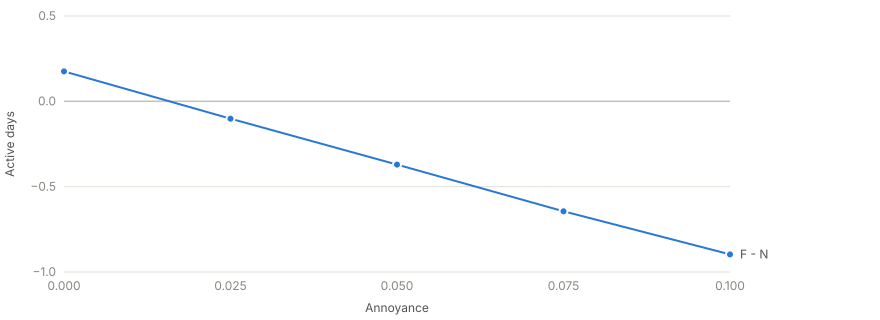

In [ ]:
flip = policy["flips"]["annoyance"]["F-N"]
display(
    SVG(
        svg.line_chart(
            flip["values"],
            [svg.Series("F - N", flip["estimates"])],
            "Annoyance",
            "Active days",
            "One push a day minus no pushes along annoyance",
            lambda e: build.interval(e, 3),
            standalone=True,
        )
    )
)

Across the main sweep, the lift is compared with the band of published program effects (METHODS 11.4; results in D034). The band of each setting is recomputed from its interval.

In [ ]:
low, high = policy["band_F_over_N"]["bounds"]


def band(entry):
    if entry["ci_high"] < low:
        return "below"
    if entry["ci_low"] > high:
        return "above"
    if entry["ci_low"] >= low and entry["ci_high"] <= high:
        return "inside"
    return "straddling"


main = [s for s in policy["settings"] if s["sweep"] == "main"]
counts = pd.Series([band(s["daily_lift_F_over_N"]) for s in main]).value_counts()
assert counts.to_dict() == policy["band_F_over_N"]["main_sweep_counts"]
counts.rename("main settings").to_frame()

,main settings
below,37
above,21
straddling,4
inside,2


## 2. Gates, budget and send time (Tier C)

Primary comparisons of M5 (METHODS 12.7). Holm across the eight sweep-level tests is recomputed from their p-values. The column of spread over SE gives the spread over ten model refits at the reference setting, divided by the mean bootstrap standard error.

In [ ]:
p_values = {
    f"{sweep}.{h}": policy["primary"][sweep][h]["sweep_average"]["p_value"]
    for sweep in ("main", "annoyance_free")
    for h in ("H1", "H2", "H3", "H4")
}
remaining, holm = True, {}
for rank, (name, p) in enumerate(sorted(p_values.items(), key=lambda kv: kv[1])):
    remaining = remaining and p <= 0.05 / (len(p_values) - rank)
    holm[name] = remaining
assert holm == policy["primary_holm"]
table(build.SWEEP_HEAD, build.sweep_rows(results, build.POLICY_ROWS))

,Comparison,Label,Sweep average,Wins / losses / neither,Refit or seed SD over SE,Holm
Id,,,,,,
H1,"Uplift gate G against response threshold S at equal volume (main sweep, difference in active days per user over 28 days)",worse on average,−0.015 (−0.021 to −0.009),1 / 29 / 34,3.3,rejected
H2,"Decomposed gate G2 against S at equal volume (main sweep, difference in active days per user over 28 days)",beats in most sampled settings,+0.056 (0.048 to 0.064),64 / 0 / 0,1.2,rejected
H3,"Gate G at half volume against one push a day at the best slot (main sweep, difference in active days per user over 28 days)",depends on the setting,+0.093 (0.052 to 0.136),43 / 19 / 2,2.2,rejected
H4,"Each user's best slot against one fixed slot (main sweep, difference in active days per user over 28 days)",no detectable difference,0.000 (−0.004 to 0.005),6 / 0 / 58,,not rejected
H1-af,"Uplift gate G against response threshold S at equal volume (annoyance-free sweep, difference in active days per user over 28 days)","loses in most sampled settings; read as worse on average with refit or seed spread (D057, post hoc)",−0.022 (−0.027 to −0.018),0 / 56 / 8,3.3,rejected
H2-af,"Decomposed gate G2 against S at equal volume (annoyance-free sweep, difference in active days per user over 28 days)","beats in most sampled settings; read as better on average with refit or seed spread (D057, post hoc)",+0.022 (0.017 to 0.026),58 / 0 / 6,1.2,rejected
H3-af,"Gate G at half volume against one push a day at the best slot (annoyance-free sweep, difference in active days per user over 28 days)",loses in most sampled settings,−0.161 (−0.179 to −0.143),0 / 64 / 0,2.2,rejected
H4-af,"Each user's best slot against one fixed slot (annoyance-free sweep, difference in active days per user over 28 days)",worse on average,−0.005 (−0.010 to −0.001),0 / 6 / 58,,rejected


## 3. Template selection (Tier C)

Equal-volume comparisons of M6. The simulator never reads the text, so these results say nothing about which copy is better. The ratio of the spread over ten seed triples to the mean bootstrap standard error is recomputed.

In [ ]:
for name in ("B1", "B2"):
    seeds = templates["seed_variability"][name]
    ratio = seeds["sd_over_seed_triples"] / seeds["mean_bootstrap_se"]
    assert abs(ratio - claims[name]["spread_over_bootstrap_se"]) < 0.05
    print(f"{name}: seed SD over bootstrap SE {ratio:.1f}")
reference_b1 = templates["seed_variability"]["B1"]["mean_over_triples"]
print("B1 at the reference, mean over seed triples:", build.interval(reference_b1, 4, signed=True))
table(build.SWEEP_HEAD, build.sweep_rows(results, build.TEMPLATE_ROWS))

B1: seed SD over bootstrap SE 17.7
B2: seed SD over bootstrap SE 19.2
B1 at the reference, mean over seed triples: +0.0015 (−0.0042 to 0.0072)


,Comparison,Label,Sweep average,Wins / losses / neither,Refit or seed SD over SE,Holm
Id,,,,,,
B1,Recovering difference softmax against uniform templates (difference in opens per user over 28 days),"beats in most sampled settings; read as better on average with refit or seed spread (D057, post hoc)",+0.079 (0.053 to 0.109),57 / 7 / 0,17.7,rejected
B2,"Recency penalty against none, same learned scores (difference in opens per user over 28 days)",depends on the setting,+0.001 (−0.002 to 0.005),28 / 28 / 8,19.2,not rejected


### Rating of the generated copy (descriptive)

By one rater, meant to be blind, though the rater may have seen the catalog first (METHODS 13.3, D039). Some kept templates make claims the data cannot back (D038); one rater cannot show that such claims do not mislead readers.

In [ ]:
rating = results["copy"]["rating"]
pd.DataFrame({k: rating[k] for k in ("kept", "passed_not_kept")})

,kept,passed_not_kept
items,60,20
clear_yes,60,19
fits_yes,54,15
misleading_yes,0,0


## 4. Per-day off-policy estimates under carryover (Tier C)

The carryover sweep (D047, D048): bias of per-day DR against simulator truth along the annoyance grid, other parameters at the reference.

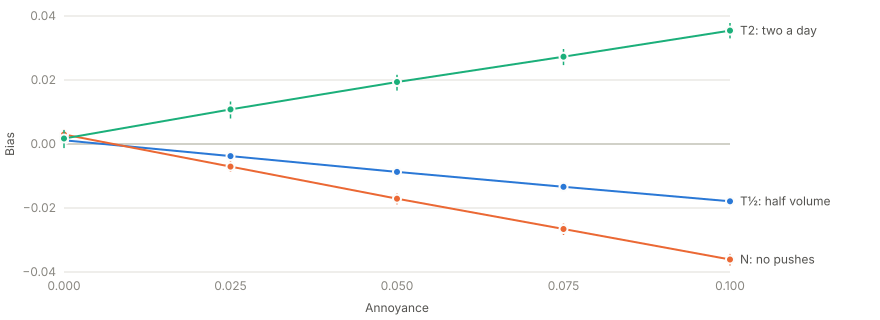

OPE-flip-T_half-DR 0.0058 (0.0014 to 0.0106)
OPE-flip-N-DR 0.0074 (0.0037 to 0.0113)


In [ ]:
xs, bias = build.ope_bias(results)
display(
    SVG(
        svg.line_chart(
            xs,
            bias,
            "Annoyance",
            "Bias",
            build.BIAS_CAPTION,
            lambda e: build.interval(e, 4, signed=True),
            standalone=True,
        )
    )
)
for key in ("OPE-flip-T_half-DR", "OPE-flip-N-DR"):
    print(key, build.interval(claims[key], 4))

Post hoc (D048): does the bias change which volume looks better? The difference no pushes minus one a day, truth against the per-day DR estimate. An ordering counts as reversed where both intervals exclude 0 with opposite signs; the counts over all settings are recomputed here.

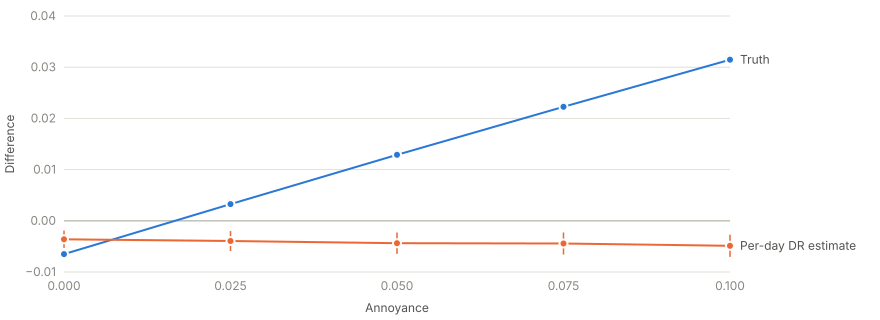

,DR ordering reversed at
Difference,
N-T,23 of 24
T_half-T,23 of 24
T2-T,22 of 24


In [ ]:
xs, ordering = build.ope_ordering(results)
display(
    SVG(
        svg.line_chart(
            xs,
            ordering,
            "Annoyance",
            "Difference",
            build.ORDERING_CAPTION,
            lambda e: build.interval(e, 4, signed=True),
            standalone=True,
        )
    )
)

orderings = carry["post_hoc"]["orderings"]


def reversed_(truth, estimate):
    t_sign = (truth["ci_low"] > 0) - (truth["ci_high"] < 0)
    e_sign = (estimate["ci_low"] > 0) - (estimate["ci_high"] < 0)
    return t_sign * e_sign == -1


rows = []
for pair in ("N-T", "T_half-T", "T2-T"):
    count = 0
    for setting in carry["settings"]:
        name, k = setting["grid"][0]
        entry = orderings[name][pair]
        count += reversed_(entry["truth"][k], entry["DR"][k])
    rows.append([pair, f"{count} of {len(carry['settings'])}"])
for pair, key in (("N-T", "OPE-order-N-T-DR"), ("T2-T", "OPE-order-T2-T-DR")):
    assert dict(rows)[pair] == claims[key]["reversed_settings"]
table(("Difference", "DR ordering reversed at"), rows)

## 5. Checks on randomized real data (Tier A)

Ranking on KuaiRand random exposures, uplift on Hillstrom and Criteo, and the off-policy estimators on the Open Bandit Dataset. No estimator passed on the full Men's campaign, so the project has no Tier B result.

In [ ]:
print(
    "post hoc, IPS against the BTS logs' own frequencies:",
    build.interval(claims["OBD-ratio-IPS"]["post_hoc_empirical_target"], 3),
)
table(build.TIER_A_HEAD, build.tier_a_rows(results))

post hoc, IPS against the BTS logs' own frequencies: 0.917 (0.848 to 0.989)


,Claim,Value,Holm
Id,,,
C1,Two-tower retrieval recalls more of a user's clicked random-exposure items in the top 200 than popularity (difference in Recall@200),0.00472 (0.00235 to 0.00704),rejected
C2,The fused fine ranker ranks random exposures worse than the two-tower score alone (difference in click GAUC),−0.0533 (−0.0580 to −0.0491),rejected
R1,"The simulator's response model ranks random exposures of users held out from fitting (AUC; these users also set the stopping round, D058)",0.694 (0.682 to 0.705),
U1,"On Hillstrom, the T-learner targets visits better than random (Qini coefficient)",0.0408 (0.0173 to 0.0637),rejected
U2,"On Hillstrom, the T-learner against the response model (difference in Qini)",0.00286 (−0.01898 to 0.02309),not rejected
U3,"On Criteo, the T-learner targets visits better than random (Qini coefficient)",0.0759 (0.0729 to 0.0790),rejected
U4,"On Criteo, the T-learner against the response model (difference in Qini)",−0.00800 (−0.01105 to −0.00472),rejected
OBD-ratio-IPS,"The estimator IPS, on real randomized logs (full Men's campaign of OBD), estimates the BTS click rate at this fraction of its on-policy value. The target is BTS with its fixed prior, which the deployed BTS was not, so the shortfall may come from the estimator or from that mismatch, and these data do not separate the two (post_hoc_empirical_target re-weights to the BTS logs' own frequencies; post_hoc_difference is its paired change from this ratio, with an interval that includes 0). Post hoc reading: the small sample has too little power to show the shortfall",0.891 (0.815 to 0.966),
OBD-ratio-DR,"The estimator DR, on real randomized logs (full Men's campaign of OBD), estimates the BTS click rate at this fraction of its on-policy value. The target is BTS with its fixed prior, which the deployed BTS was not, so the shortfall may come from the estimator or from that mismatch, and these data do not separate the two. Post hoc reading: the small sample has too little power to show the shortfall",0.897 (0.824 to 0.975),


## The core story, as it came out

In [ ]:
table(("Item", "Outcome"), build.story_rows(build.facts(results)))

,Outcome
Item,
Sending the top item to every user every day wins on clicks in week one,"Holds at the reference, as a registered secondary result without a test (METHODS 12.7): week-one opens per user are 0.104 (0.099 to 0.109) for a daily push at the best slot and 0.056 (0.052 to 0.060) for the half-volume gate, in one model fit."
It loses users to fatigue and opt-outs by week four,"Partly, in the simulator (F-N, D034). At the reference, a daily push leaves 3.89 (3.85 to 3.93) active days in week four against 4.05 (4.01 to 4.09) without pushes, and changes the daily active share by −2.3% (−2.4% to −2.2%). On the one-at-a-time grid the sign turns on annoyance (a gain below 0.016 (0.015 to 0.017)) and the base rate (a gain above 0.18 (0.17 to 0.19)), never on fatigue or opt-out."
"An uplift gate under a volume budget, at each user's active slot, with a bandit choosing copy, sends fewer pushes and keeps more users active","Not as stated, in the simulator (H1 to H4, B1, B2; D034, D040). The T-learner gate loses to a response threshold at equal volume; the decomposed gate G2 wins, partly through the simulator's structure, which G2 assumes. At half volume the gate beats a daily push in 43 of 64 main settings and loses in 19 (per-setting verdicts understate fit noise), and wins in none without annoyance. The best slot adds nothing detectable. The bandit beats uniform templates on average; the recency penalty has no detectable effect. The simulator does not read the copy, so this says nothing about which text works."
"The conclusion holds across most plausible settings, and the report shows where it flips","Partly (F-N, H3; D034). Flips are located for F-N along annoyance at 0.016 (0.015 to 0.017) and the base rate at 0.18 (0.17 to 0.19), and for H3 along annoyance at 0.013 (0.012 to 0.015); every other crossing of H1 to H4 is unresolved. Crossing intervals cover user sampling with the grid's seeds fixed, not the interpolation or model-fit randomness (D034)."
Every number carries an evidence tier,"Holds for the results in the evidence matrix, each Tier A or C with an interval or a verdict, and there is no Tier B result (D046). Counts of the generated copy and its rating are descriptive; registered verdicts later overturned are kept as history."
